***dataset:fifaplayer data***  
1.input  -- needed inuput  
2.output --random group making  
3.donot check missking value in unsupervised method  
4.here not replace missing value ,do delete missing data(dropna())  
5.nonnull value--delete---check describr()--all mean value is same after delete missing data  
6.use standardized process  
7.here not split input,,output test train data  
8.fit player features-->input  
9.fit dataset  
10.create image for how to make multiple group data  


In [10]:
import pandas as pd 
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans


In [11]:
fifa_data = pd.read_csv("C:\\techpanda\\course\\ML\\data\\k-cluster\\Fifa_Players.csv")
fifa_data

C:\Users\Admin\AppData\Local\Temp\ipykernel_37088\3282596598.py:1: DtypeWarning: Columns (25: nation_position, 108: nation_logo_url) have mixed types. Specify dtype option on import or set low_memory=False.
  fifa_data = pd.read_csv("C:\\techpanda\\course\\ML\\data\\k-cluster\\Fifa_Players.csv")


,sofifa_id,player_url,short_name,long_name,player_positions,overall,potential,value_eur,wage_eur,age,...,lcb,cb,rcb,rb,gk,player_face_url,club_logo_url,club_flag_url,nation_logo_url,nation_flag_url
0,158023,https://sofifa.com/player/158023/lionel-messi/...,L. Messi,Lionel Andrés Messi Cuccittini,"RW, ST, CF",93,93,78000000.0,320000.0,34,...,50+3,50+3,50+3,61+3,19+3,https://cdn.sofifa.net/players/158/023/22_120.png,https://cdn.sofifa.net/teams/73/60.png,https://cdn.sofifa.net/flags/fr.png,https://cdn.sofifa.net/teams/1369/60.png,https://cdn.sofifa.net/flags/ar.png
1,188545,https://sofifa.com/player/188545/robert-lewand...,R. Lewandowski,Robert Lewandowski,ST,92,92,119500000.0,270000.0,32,...,60+3,60+3,60+3,61+3,19+3,https://cdn.sofifa.net/players/188/545/22_120.png,https://cdn.sofifa.net/teams/21/60.png,https://cdn.sofifa.net/flags/de.png,https://cdn.sofifa.net/teams/1353/60.png,https://cdn.sofifa.net/flags/pl.png
2,20801,https://sofifa.com/player/20801/c-ronaldo-dos-...,Cristiano Ronaldo,Cristiano Ronaldo dos Santos Aveiro,"ST, LW",91,91,45000000.0,270000.0,36,...,53+3,53+3,53+3,60+3,20+3,https://cdn.sofifa.net/players/020/801/22_120.png,https://cdn.sofifa.net/teams/11/60.png,https://cdn.sofifa.net/flags/gb-eng.png,https://cdn.sofifa.net/teams/1354/60.png,https://cdn.sofifa.net/flags/pt.png
3,190871,https://sofifa.com/player/190871/neymar-da-sil...,Neymar Jr,Neymar da Silva Santos Júnior,"LW, CAM",91,91,129000000.0,270000.0,29,...,50+3,50+3,50+3,62+3,20+3,https://cdn.sofifa.net/players/190/871/22_120.png,https://cdn.sofifa.net/teams/73/60.png,https://cdn.sofifa.net/flags/fr.png,NaN,https://cdn.sofifa.net/flags/br.png
4,192985,https://sofifa.com/player/192985/kevin-de-bruy...,K. De Bruyne,Kevin De Bruyne,"CM, CAM",91,91,125500000.0,350000.0,30,...,69+3,69+3,69+3,75+3,21+3,https://cdn.sofifa.net/players/192/985/22_120.png,https://cdn.sofifa.net/teams/10/60.png,https://cdn.sofifa.net/flags/gb-eng.png,https://cdn.sofifa.net/teams/1325/60.png,https://cdn.sofifa.net/flags/be.png
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19234,261962,https://sofifa.com/player/261962/defu-song/220002,Song Defu,宋德福,CDM,47,52,70000.0,1000.0,22,...,46+2,46+2,46+2,48+2,15+2,https://cdn.sofifa.net/players/261/962/22_120.png,https://cdn.sofifa.net/teams/112541/60.png,https://cdn.sofifa.net/flags/cn.png,NaN,https://cdn.sofifa.net/flags/cn.png
19235,262040,https://sofifa.com/player/262040/caoimhin-port...,C. Porter,Caoimhin Porter,CM,47,59,110000.0,500.0,19,...,44+2,44+2,44+2,48+2,14+2,https://cdn.sofifa.net/players/262/040/22_120.png,https://cdn.sofifa.net/teams/445/60.png,https://cdn.sofifa.net/flags/ie.png,NaN,https://cdn.sofifa.net/flags/ie.png
19236,262760,https://sofifa.com/player/262760/nathan-logue/...,N. Logue,Nathan Logue-Cunningham,CM,47,55,100000.0,500.0,21,...,45+2,45+2,45+2,47+2,12+2,https://cdn.sofifa.net/players/262/760/22_120.png,https://cdn.sofifa.net/teams/111131/60.png,https://cdn.sofifa.net/flags/ie.png,NaN,https://cdn.sofifa.net/flags/ie.png
19237,262820,https://sofifa.com/player/262820/luke-rudden/2...,L. Rudden,Luke Rudden,ST,47,60,110000.0,500.0,19,...,26+2,26+2,26+2,32+2,15+2,https://cdn.sofifa.net/players/262/820/22_120.png,https://cdn.sofifa.net/teams/111131/60.png,https://cdn.sofifa.net/flags/ie.png,NaN,https://cdn.sofifa.net/flags/ie.png


In [16]:
# to short the data bcz its have lot of data

import pandas as pd
player_feature = pd.DataFrame(pd.read_csv("C:\\techpanda\\course\\ML\\data\\k-cluster\\Fifa_Players.csv",usecols=['overall','potential','value_eur','wage_eur','age']))
player_feature

,overall,potential,value_eur,wage_eur,age
0,93,93,78000000.0,320000.0,34
1,92,92,119500000.0,270000.0,32
2,91,91,45000000.0,270000.0,36
3,91,91,129000000.0,270000.0,29
4,91,91,125500000.0,350000.0,30
...,...,...,...,...,...
19234,47,52,70000.0,1000.0,22
19235,47,59,110000.0,500.0,19
19236,47,55,100000.0,500.0,21
19237,47,60,110000.0,500.0,19


In [17]:
player_feature.describe()

,overall,potential,value_eur,wage_eur,age
count,19239.000000,19239.000000,1.916500e+04,19178.000000,19239.000000
mean,65.772182,71.079370,2.850452e+06,9017.989363,25.210822
std,6.880232,6.086213,7.613700e+06,19470.176724,4.748235
min,47.000000,49.000000,9.000000e+03,500.000000,16.000000
25%,61.000000,67.000000,4.750000e+05,1000.000000,21.000000
50%,66.000000,71.000000,9.750000e+05,3000.000000,25.000000
75%,70.000000,75.000000,2.000000e+06,8000.000000,29.000000
max,93.000000,95.000000,1.940000e+08,350000.000000,54.000000


In [18]:
# check missing value
player_feature.info()

<class 'pandas.DataFrame'>
RangeIndex: 19239 entries, 0 to 19238
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   overall    19239 non-null  int64  
 1   potential  19239 non-null  int64  
 2   value_eur  19165 non-null  float64
 3   wage_eur   19178 non-null  float64
 4   age        19239 non-null  int64  
dtypes: float64(2), int64(3)
memory usage: 751.7 KB


In [19]:
player_feature.isna().sum()

overall       0
potential     0
value_eur    74
wage_eur     61
age           0
dtype: int64

In [20]:
player_feature.shape

(19239, 5)

In [23]:
#here delete missing data
player_feature = player_feature.dropna()

In [24]:
player_feature.shape

(19165, 5)

In [25]:
player_feature.describe()

,overall,potential,value_eur,wage_eur,age
count,19165.000000,19165.000000,1.916500e+04,19165.000000,19165.000000
mean,65.760188,71.079990,2.850452e+06,9021.721889,25.190034
std,6.882803,6.087721,7.613700e+06,19476.005074,4.727515
min,47.000000,49.000000,9.000000e+03,500.000000,16.000000
25%,61.000000,67.000000,4.750000e+05,1000.000000,21.000000
50%,66.000000,71.000000,9.750000e+05,3000.000000,25.000000
75%,70.000000,75.000000,2.000000e+06,8000.000000,29.000000
max,93.000000,95.000000,1.940000e+08,350000.000000,43.000000


In [27]:
    
from sklearn.preprocessing import StandardScaler
scalar = StandardScaler()
player_feature_se = scalar.fit_transform(player_feature)
player_feature_se

array([[ 3.95776568,  3.60078658,  9.87056351, 15.96766844,  1.86359972],
       [ 3.81247225,  3.4365172 , 15.32140647, 13.40033986,  1.44053345],
       [ 3.66717883,  3.27224782,  5.53615826, 13.40033986,  2.28666598],
       ...,
       [-2.725732  , -2.64144996, -0.36125978, -0.4375612 , -0.886331  ],
       [-2.725732  , -1.82010304, -0.35994632, -0.4375612 , -1.30939726],
       [-2.725732  , -1.82010304, -0.35994632, -0.4375612 , -1.30939726]],
      shape=(19165, 5))

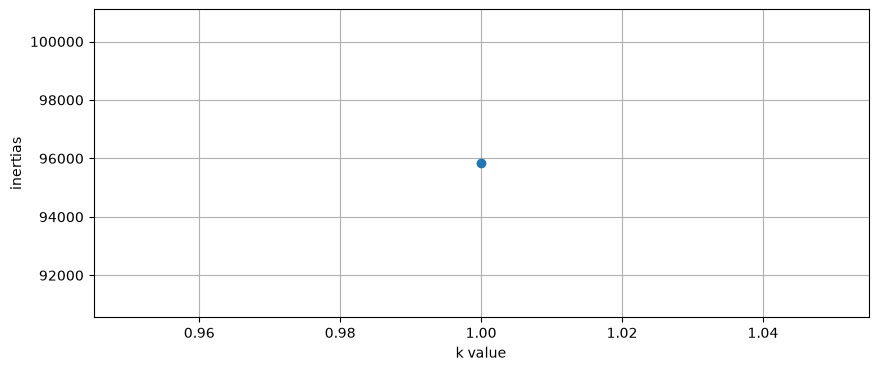

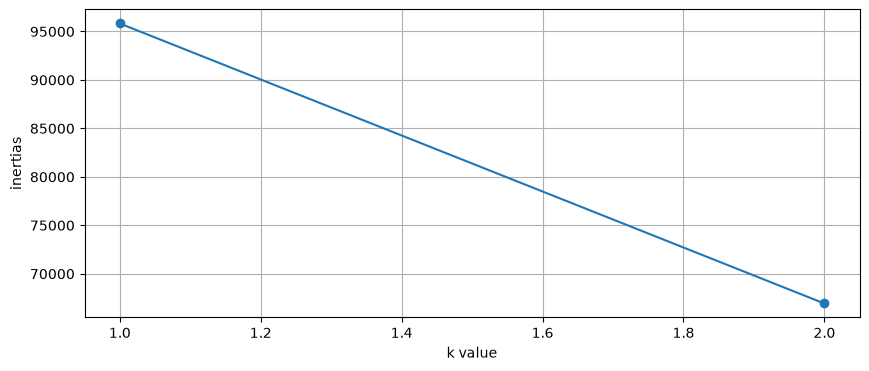

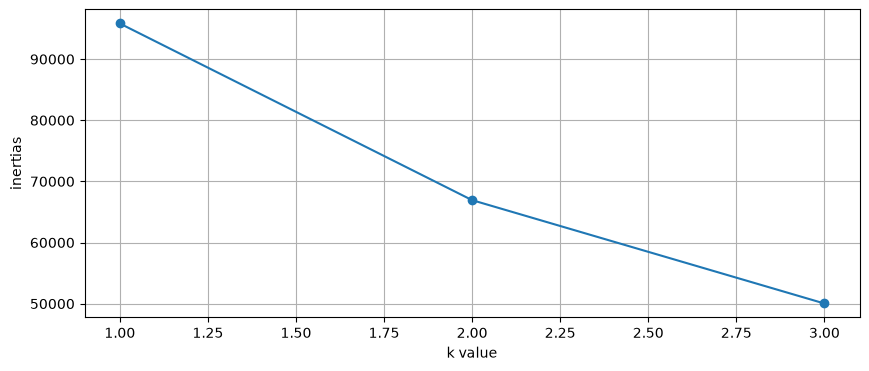

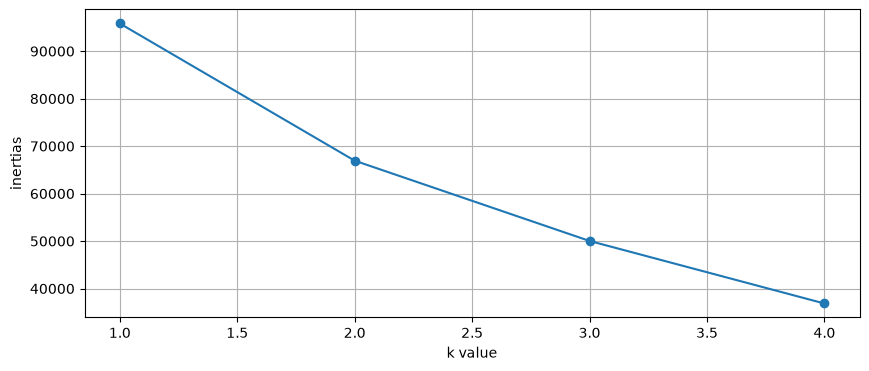

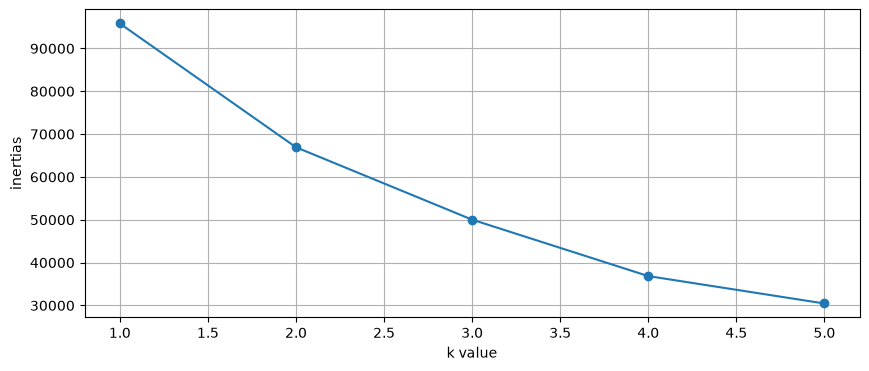

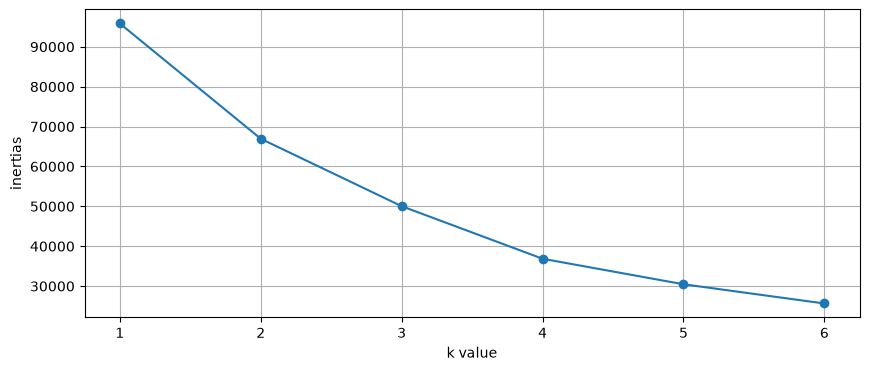

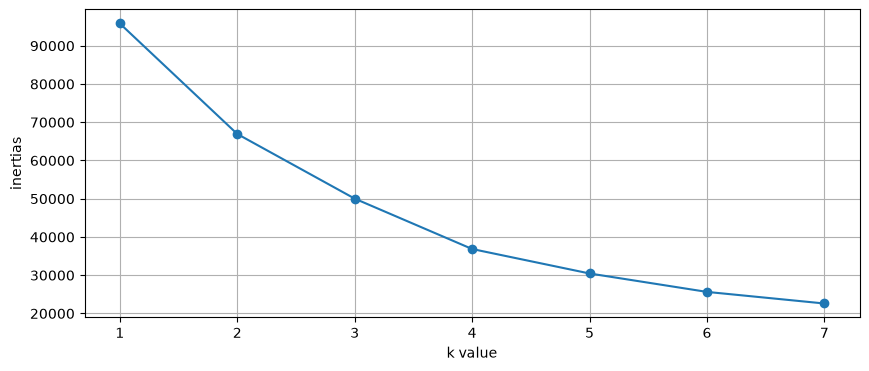

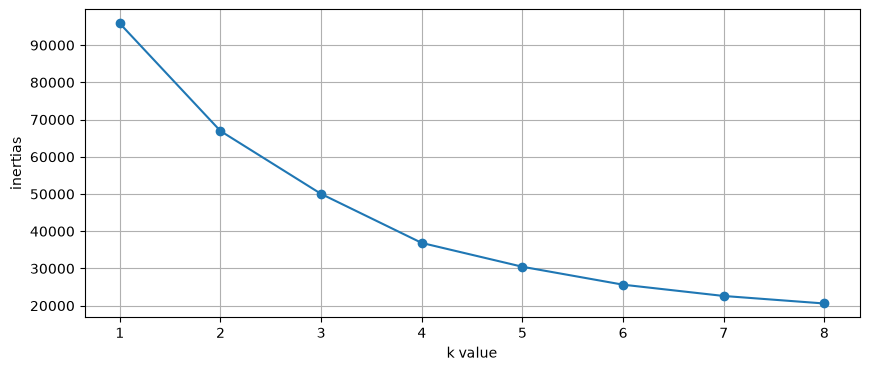

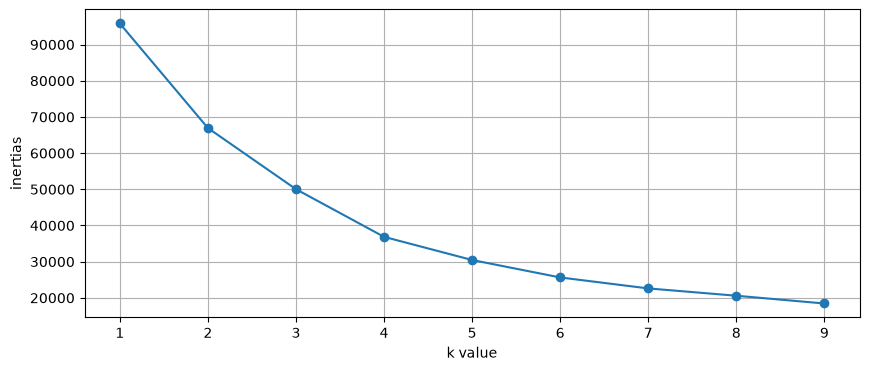

In [59]:
# to convet image
# kmean algorithm using
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

def best_k_means(data,kmax): # kmax-->maximum cluster value
    mean=[]
    inertias = []
    for k in range(1,kmax):
        kmeans=KMeans(n_clusters=k) # to set number of cluster
        kmeans.fit(data)  # fit-->to apply k mean algorithm to dataset  
        mean.append(k) 
        inertias.append(kmeans.inertia_) # inertia---->cluster all euclidian distance(to cal sum of square)

        # elbow plot
        # fig=plt.subplots(figsize=(12,5))
        plt.figure(figsize=(10, 4))
        
        plt.plot(mean, inertias, 'o-')
        plt.xlabel("k value")
        plt.ylabel("inertias")
        plt.grid(True)
        plt.show();

best_k_means(player_feature_se, 10) # here put 10 value

In [50]:
kmeans=KMeans(n_clusters=2) #here k value is 2 means 1 to 2 ,2 to 3 ....so k=3 
# 2 means 2 group 
# 3 means 3 group

In [51]:
kmeans.fit(player_feature_se)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",2
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",None
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](2, 5)",

In [52]:
# create new cloumn in raw data(after choose usecolumn data)
player_feature.insert(5,'k2',kmeans.labels_) # (cloumn ,title)---(1 2 category)

In [53]:
player_feature

,overall,potential,value_eur,wage_eur,age,k2,k3
0,93,93,78000000.0,320000.0,34,1,2
1,92,92,119500000.0,270000.0,32,1,2
2,91,91,45000000.0,270000.0,36,1,2
3,91,91,129000000.0,270000.0,29,1,2
4,91,91,125500000.0,350000.0,30,1,2
...,...,...,...,...,...,...,...
19234,47,52,70000.0,1000.0,22,0,1
19235,47,59,110000.0,500.0,19,0,1
19236,47,55,100000.0,500.0,21,0,1
19237,47,60,110000.0,500.0,19,0,1


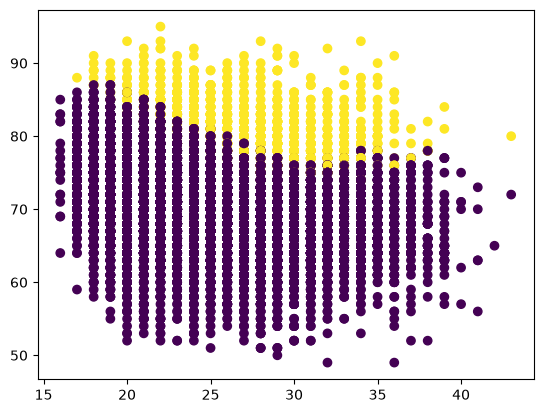

In [55]:
# to craete scatter image 
plt.scatter(x=player_feature['age'],y=player_feature['potential'],c=player_feature['k2'])

In [56]:
kmeans=KMeans(n_clusters=4)
kmeans.fit(player_feature_se)
player_feature.insert(7,'k4',kmeans.labels_) 
player_feature

,overall,potential,value_eur,wage_eur,age,k2,k3,k4
0,93,93,78000000.0,320000.0,34,1,2,1
1,92,92,119500000.0,270000.0,32,1,2,1
2,91,91,45000000.0,270000.0,36,1,2,1
3,91,91,129000000.0,270000.0,29,1,2,1
4,91,91,125500000.0,350000.0,30,1,2,1
...,...,...,...,...,...,...,...,...
19234,47,52,70000.0,1000.0,22,0,1,3
19235,47,59,110000.0,500.0,19,0,1,3
19236,47,55,100000.0,500.0,21,0,1,3
19237,47,60,110000.0,500.0,19,0,1,3


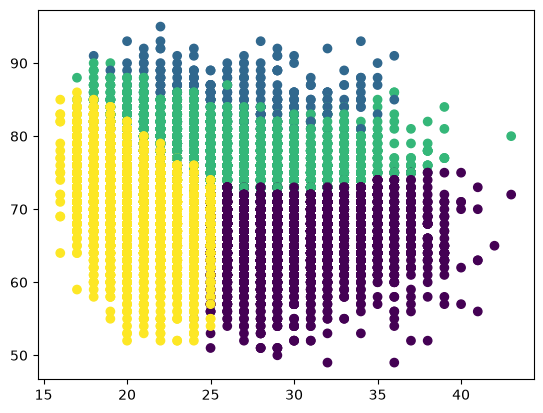

In [57]:
plt.scatter(x=player_feature['age'],y=player_feature['potential'],c=player_feature['k4'])